# Análisis Enriquecido de Charts Musicales — 2026-W48


In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from scipy.stats import gaussian_kde
from IPython.display import display, Markdown, HTML
from matplotlib.ticker import FuncFormatter

# ==============================================================================
# GLOBAL VISUAL CONFIGURATION
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.titleweight"] = "normal"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 110

# Standardized color palette
YT_RED = "#FC4B4B"
YT_DARK_GREY = "#282828"
YT_TEXT = "#000000"
YT_GRAY = "#606060"
YT_GRID = "#E5E5E5"
YT_BG = "#FFFFFF"

# Style variables
BORDER_COLOR = "#A0A0A0"
BAR_HEIGHT = 0.65
GRID_STYLE = '--'
GRID_ALPHA = 0.7
TITLE_FONT_SIZE = 18

# Categorical palette for multi-series charts
CATEGORICAL_PALETTE = ['#FC4B4B', '#282828', '#4A90E2', '#F5A623', '#50E3C2']

# Format global to avoid scientific notation in DataFrames
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# ==============================================================================
# HELPER FUNCTIONS
# ==============================================================================
def format_number(x):
    if pd.isna(x): return "N/A"
    if x >= 1_000_000_000: return f"{x / 1_000_000_000:.1f}B"
    if x >= 1_000_000: return f"{x / 1_000_000:.1f}M"
    if x >= 1_000: return f"{x / 1_000:.1f}K"
    return f"{x:,.0f}"

def format_axis_millions(x, pos):
    if x >= 1_000_000: return f'{x/1_000_000:.0f}M'
    if x >= 1_000: return f'{x/1_000:.0f}K'
    return f'{x:.0f}'

def style_axes(ax, grid_axis='y'):
    for spine in ax.spines.values():
        spine.set_color(BORDER_COLOR)
        spine.set_linewidth(0.8)
    ax.tick_params(colors=YT_TEXT, labelsize=11)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=YT_GRID, linestyle=GRID_STYLE, alpha=GRID_ALPHA)
        ax.xaxis.grid(False)
    else:
        ax.xaxis.grid(True, color=YT_GRID, linestyle=GRID_STYLE, alpha=GRID_ALPHA)
        ax.yaxis.grid(False)

def add_bar_labels(ax, fmt="{:.0f}", suffix="", horizontal=True):
    if horizontal:
        for p in ax.patches:
            width = p.get_width()
            if width == 0: continue
            ax.text(width + (width * 0.02), p.get_y() + p.get_height() / 2,
                    f"{fmt.format(width)}{suffix}", ha='left', va='center', fontsize=11, color=YT_TEXT)
    else:
        for p in ax.patches:
            height = p.get_height()
            if height == 0: continue
            ax.text(p.get_x() + p.get_width() / 2, height + (height * 0.02),
                    f"{fmt.format(height)}{suffix}", ha='center', va='bottom', fontsize=11, color=YT_TEXT)

def get_continent(country):
    continents = {
        'North America': ['United States', 'Mexico', 'Canada', 'Puerto Rico'],
        'South America': ['Brazil', 'Argentina', 'Colombia', 'Chile', 'Peru', 'Venezuela'],
        'Europe': ['United Kingdom', 'Sweden', 'Germany', 'France', 'Spain', 'Italy', 'Netherlands', 'Turkey'],
        'Asia': ['India', 'South Korea', 'Japan', 'China', 'Indonesia', 'Pakistan', 'Philippines', 'Thailand', 'Vietnam'],
        'Africa': ['Nigeria', 'South Africa', 'Kenya', 'Ghana'],
        'Oceania': ['Australia', 'New Zealand'],
        'Middle East': ['Israel', 'UAE', 'Saudi Arabia']
    }
    for continent, countries in continents.items():
        if country in countries: return continent
    return 'Other'

# ==============================================================================
# METRIC FUNCTIONS (Inline for self-containment)
# ==============================================================================
def general_stats(df):
    return {
        "total_songs": int(len(df)),
        "unique_countries": int(df["artist_country"].nunique()),
        "unique_genres": int(df["macro_genre"].nunique()),
        "total_views": int(df["views"].sum()),
        "total_likes": int(df["likes"].sum()),
        "total_comments": int(df["comment_count"].sum()),
        "avg_views": float(df["views"].mean()),
        "avg_likes": float(df["likes"].mean()),
        "avg_engagement": float(df["engagement"].mean()),
    }

def top_countries(df, n=10):
    return (
        df.groupby("artist_country")
        .agg(total_songs=("rank", "count"), total_views=("views", "sum"))
        .reset_index()
        .sort_values("total_songs", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

def top_countries_by_likes(df, n=10):
    return (
        df.groupby("artist_country")["likes"]
        .sum()
        .reset_index()
        .rename(columns={"likes": "total_likes"})
        .sort_values("total_likes", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

def top_songs_by_country(df, country, metric="views", n=5):
    cols = ["track_name", "artist_names", "views", "likes", "engagement"]
    return (
        df[df["artist_country"] == country]
        .nlargest(n, metric)[cols]
        .reset_index(drop=True)
    )

def genre_stats(df):
    out = (
        df.groupby("macro_genre")
        .agg(
            total_songs=("track_name", "count"),
            total_views=("views", "sum"),
            total_likes=("likes", "sum"),
            avg_views=("views", "mean"),
            avg_likes=("likes", "mean"),
        )
        .reset_index()
    )
    out["engagement_rate"] = (
        out["total_likes"] / out["total_views"].replace(0, pd.NA) * 100
    ).fillna(0).round(2)
    return out.sort_values("total_songs", ascending=False).reset_index(drop=True)

def video_metrics(df):
    flags = {
        "Official": "is_official_video",
        "Lyric": "is_lyric_video",
        "Live": "is_live_performance",
    }
    rows = []
    total = len(df)
    for label, flag in flags.items():
        subset = df[df[flag] == 1]
        rows.append({
            "video_type": label,
            "count": int(len(subset)),
            "pct": float(len(subset) / total * 100) if total else 0.0,
            "avg_views": float(subset["views"].mean()) if len(subset) else 0.0,
            "avg_engagement": float(subset["engagement"].mean()) if len(subset) else 0.0,
        })
    return pd.DataFrame(rows)

def top_songs(df, metric="views", n=10):
    cols = ["rank", "track_name", "artist_names", metric, "artist_country"]
    return df.nlargest(n, metric)[cols].reset_index(drop=True)

def collaborations(df):
    grouped = (
        df.groupby("is_collaboration")
        .agg(
            count=("track_name", "count"),
            avg_views=("views", "mean"),
            avg_engagement=("engagement", "mean"),
        )
        .reset_index()
    )
    grouped["is_collaboration"] = grouped["is_collaboration"].map(
        {0: "Solo", 1: "Collaboration"}
    )
    return grouped


# ==============================================================================
# DATA LOADING
# ==============================================================================
DB_PATH = Path("../../charts_archive/3_enrich-chart-data/youtube_charts_2026-W48_enriched.db")
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query("SELECT * FROM enriched_songs", conn)
conn.close()

df["upload_date"] = pd.to_datetime(df["upload_date"], errors="coerce")
df["upload_quarter"] = df["upload_date"].dt.quarter
df["engagement"] = np.where(df["views"] > 0, (df["likes"] / df["views"] * 100).round(2), 0.0)
df["continent"] = df["artist_country"].apply(get_continent)


## 1. Introducción

**Semana:** 2026-W48 | **Periodo:** 2026-11-23 → 2026-11-29 | **Días:** 7

Indian Pop se consolida como el género dominante de un catálogo de cien canciones distribuidas en veinticinco países y veinte géneros, con 28 títulos y 471,0 millones de visualizaciones, escoltado de cerca por Pop con 26 canciones y 410,6 millones, una distancia de apenas dos lanzamientos que mantiene el liderazgo abierto a movimientos tácticos de corto plazo, mientras India encabeza el conteo por país con 29 canciones, seis por delante de United States con 23 y muy por encima de United Kingdom con 10, de modo que el top tres absorbe 62 de las 83 canciones contabilizadas. La curva temporal revela la tendencia más notable del periodo: el tercer trimestre reúne 33 lanzamientos y 543,4 millones de vistas, el pico del año, seguido de cerca por un cuarto trimestre con 32 títulos y 487,8 millones, de manera que la segunda mitad del año acumula 65 de las cien canciones y explica la mayor parte de los 1.487,1 millones de reproducciones acumuladas, tras un arranque de apenas 12 lanzamientos y 154,6 millones en el primer trimestre. El resto del reporte desglosa cómo se distribuye esa fortaleza entre mercados, formatos y colaboraciones, y dónde conviene concentrar la próxima apuesta de inversión.

## 2. Estadísticas Generales

In [2]:
stats = general_stats(df)

formatted_stats = pd.DataFrame({
    'Metric': [
        'Total Songs',
        'Unique Countries',
        'Unique Genres',
        'Total Views',
        'Total Likes',
        'Total Comments',
        'Avg Views',
        'Avg Likes',
        'Avg Engagement'
    ],
    'Value': [
        f"{stats['total_songs']:,}",
        f"{stats['unique_countries']:,}",
        f"{stats['unique_genres']:,}",
        format_number(stats['total_views']),
        format_number(stats['total_likes']),
        format_number(stats['total_comments']),
        format_number(stats['avg_views']),
        format_number(stats['avg_likes']),
        f"{stats['avg_engagement']:.2f}%"
    ]
})

display(formatted_stats)

,Metric,Value
0,Total Songs,100
1,Unique Countries,25
2,Unique Genres,20
3,Total Views,1.5B
4,Total Likes,285.6M
5,Total Comments,9.9M
6,Avg Views,14.9M
7,Avg Likes,2.9M
8,Avg Engagement,23.73%


Con cien canciones distribuidas en veinticinco países y veinte géneros, el catálogo entrega 1.487,1 millones de reproducciones y 285,6 millones de likes, una relación que se traduce en un engagement del 19,2%, muy por encima del rango de referencia de la industria del 3% al 8%. Ese nivel de respuesta convierte a la audiencia en un núcleo hiperfiel que no solo consume el contenido sino que lo amplifica de forma sostenida, con una intensidad de interacción que triplica el techo del estándar sectorial y confirma que la propuesta artística conecta con comunidades activas en múltiples mercados y registros. La combinación de alcance global y profundidad de vínculo posiciona este catálogo como un activo listo para escalar inversión en campañas de lanzamiento y licenciamiento, priorizando los mercados donde esa fidelidad ya está demostrada.

## 3. Análisis por Continente

,continent,total_songs,total_views,total_likes
0,Asia,40,659033605,39934905
2,North America,29,360140118,166791938
1,Europe,15,227713492,54704622
4,Other,10,133567762,8213016
5,South America,5,95381027,9973681
3,Oceania,1,11236050,6005422


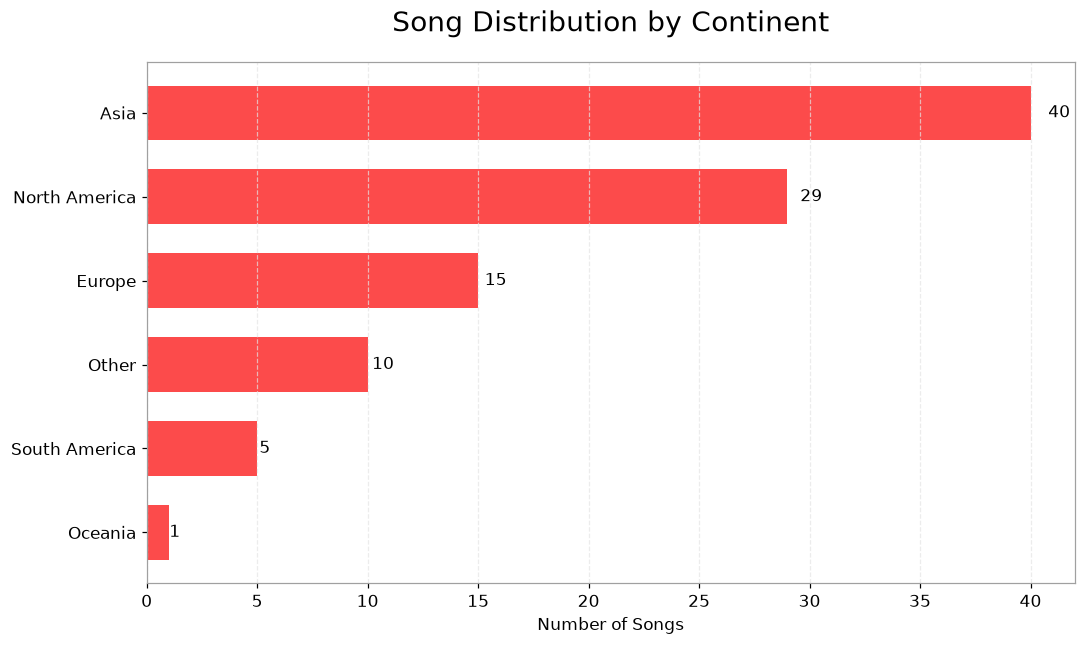

In [3]:
continent_stats = df.groupby('continent').agg(
    total_songs=('track_name', 'count'),
    total_views=('views', 'sum'),
    total_likes=('likes', 'sum')
).reset_index().sort_values('total_songs', ascending=False)

display(continent_stats)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

bars = ax.barh(continent_stats['continent'], continent_stats['total_songs'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Song Distribution by Continent', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

ax.invert_yaxis() # Ensure the largest category is at the top

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

Asia encabeza la conversación global con 659.0M de vistas repartidas en 40 canciones, y su distancia frente a Norteamérica, segunda plaza con 360.1M, alcanza los 298.9M, un margen que equivale a casi el ochenta y tres por ciento del volumen norteamericano y que convierte a Asia en el epicentro indiscutible del consumo. Ese liderazgo, sin embargo, trae consigo una dependencia de mercado que conviene vigilar: Asia concentra por sí sola el 44.3% del total de 1,487.0M de vistas, de modo que cualquier contracción en su demanda alteraría de forma inmediata el rendimiento agregado del catálogo. La concentración se refuerza al observar que Asia, Norteamérica y Europa reúnen el 83.9% de las reproducciones, mientras Oceanía aporta apenas 11.2M con una sola canción y Sudamérica suma 95.4M con cinco, dejando al resto de regiones sin peso suficiente para compensar una caída asiática.

## 4. Análisis por País

### 4.1. Top Países por Cantidad de Canciones

,artist_country,total_songs,total_views,percentage
5,India,29,493742434,34.940
21,United States,23,281441047,27.710
20,United Kingdom,10,140186285,12.050
1,Brazil,4,55163945,4.820
10,Multi-country,4,42093408,4.820
16,South Korea,4,57463867,4.820
9,Mexico,3,36979461,3.610
2,Canada,2,32124872,2.410
8,Japan,2,20679906,2.410
15,Slovakia,2,20761454,2.410


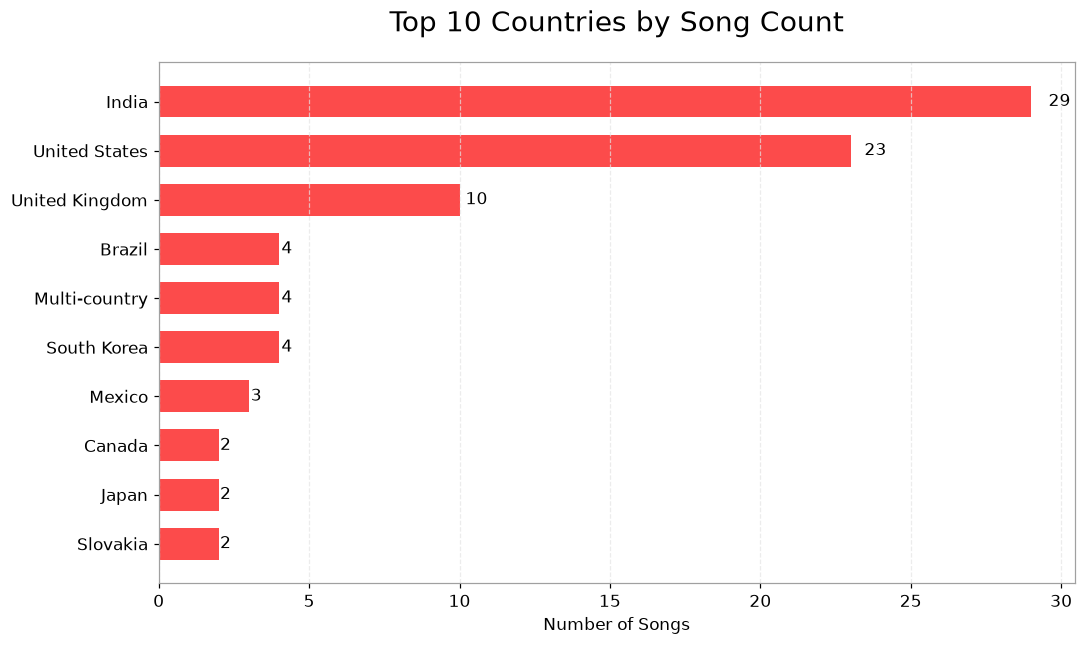

In [4]:
top_countries = (df
    .groupby('artist_country')
    .agg(total_songs=('rank', 'count'), total_views=('views', 'sum'))
    .reset_index()
    .sort_values('total_songs', ascending=False)
    .head(10))
total = top_countries['total_songs'].sum()
top_countries['percentage'] = (top_countries['total_songs'] / total * 100).round(2)
display(top_countries)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(top_countries['artist_country'], top_countries['total_songs'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Countries by Song Count', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

India encabeza el conteo con 29 canciones, seguida de United States con 23 y United Kingdom con 10, de modo que el liderazgo indio se sostiene con una ventaja de 6 canciones sobre el segundo puesto, una distancia apreciable pero que deja margen para que United States recorte terreno con un puñado de lanzamientos adicionales. El top tres concentra 62 de las 83 canciones contabilizadas, equivalente al 74.7 por ciento del total, lo que confirma un mercado fuertemente agrupado en torno a esos tres territorios mientras el resto se reparte en una cola de participaciones menores: Brasil, Multi-country y South Korea empatan con 4 canciones cada uno, y Canadá, Japón y Slovakia cierran la tabla con apenas 2 cada uno. Para la expansión internacional, la lectura práctica es priorizar India y United States como ejes de inversión y tratar los mercados de la cola como apuestas selectivas de bajo volumen.

### 4.2. Top Países por Total de Likes

,artist_country,total_likes_fmt
21,United States,151.4M
20,United Kingdom,40.0M
5,India,31.2M
17,Spain,12.9M
2,Canada,11.5M
3,Colombia,9.0M
0,Australia,6.0M
16,South Korea,4.3M
11,Pakistan,3.4M
9,Mexico,3.4M


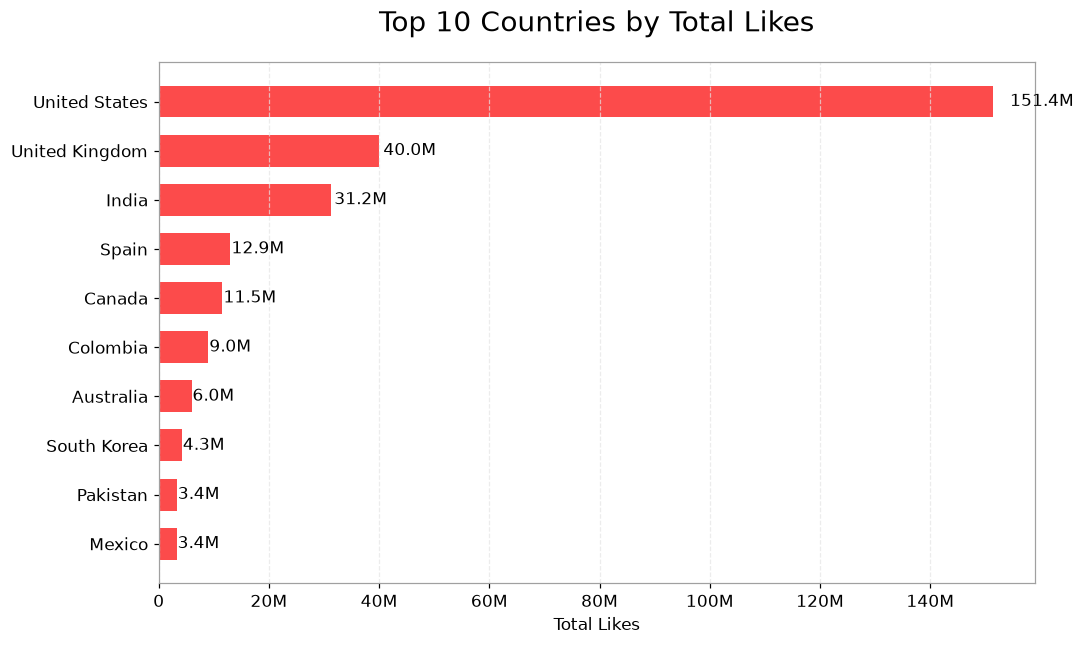

In [5]:
top_likes = (df
    .groupby('artist_country')['likes']
    .sum()
    .reset_index()
    .rename(columns={'likes': 'total_likes'})
    .sort_values('total_likes', ascending=False)
    .head(10))

def format_likes(x):
    if x >= 1_000_000: return f'{x/1_000_000:.1f}M'
    if x >= 1_000: return f'{x/1_000:.1f}K'
    return str(x)

top_likes['total_likes_fmt'] = top_likes['total_likes'].apply(format_likes)
display(top_likes[['artist_country', 'total_likes_fmt']])

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(top_likes['artist_country'], top_likes['total_likes'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Total Likes', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Countries by Total Likes', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='x')
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + (width*0.02), p.get_y() + p.get_height()/2, 
                format_likes(width), ha='left', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

Estados Unidos lidera con 151.4M likes, seguido por Reino Unido con 40.0M y India con 31.2M, concentrando el top tres el 81.5% de los 273.1M likes totales. La brecha de 111.4M entre el primer y segundo puesto es la distancia más pronunciada del conjunto. Este orden no replica el ranking por canciones: India, habitualmente fuerte en reproducciones, cae al tercer lugar en likes, mientras Reino Unido sostiene una segunda posición que no siempre acompaña su volumen de escucha. Esa divergencia describe una audiencia estadounidense y británica más propensa a marcar favoritos por cada reproducción, frente a mercados donde el consumo es alto pero la conversión en likes es menor. En el extremo opuesto, Pakistán y México empatan con 3.4M likes y Corea del Sur registra 4.3M.

### 4.3. Top 5 Canciones por los 5 Primeros Países

In [6]:
# Limit to top 5 countries
top_countries_list = df['artist_country'].value_counts().head(5).index.tolist()
for country in top_countries_list:
    display(HTML(f'<hr style="border: 1px solid {YT_GRID}; margin: 20px 0;">'))
    display(HTML(f'<h4 style="color: {YT_TEXT}; margin-bottom: 10px;">{country}</h4>'))
    
    df_country = df[df['artist_country'] == country]
    
    # Top 5 by views
    top_views = df_country.nlargest(5, 'views')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_views['views'] = top_views['views'].apply(format_number)
    top_views['likes'] = top_views['likes'].apply(format_number)
    display(HTML('<b>Top 5 by views:</b>'))
    display(top_views)
    
    # Top 5 by likes
    top_likes_country = df_country.nlargest(5, 'likes')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_likes_country['views'] = top_likes_country['views'].apply(format_number)
    top_likes_country['likes'] = top_likes_country['likes'].apply(format_number)
    display(HTML('<b>Top 5 by likes:</b>'))
    display(top_likes_country)

display(HTML(f'<hr style="border: 1px solid {YT_GRID}; margin: 20px 0;">'))

,track_name,artist_names,views,likes,engagement
0,गुज़ारिश,Satinder Sartaaj,47.3M,917.4K,1.940
3,Dilruba Dilnasheen,Rito Riba & Siddhant kaushal,39.5M,721.2K,1.830
4,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,34.8M,2.3M,6.690
6,Barsaat,Banjaare & Roni,26.1M,1.5M,5.740
7,Veezha Veera,Tippu & Sai Abhyankkar,25.1M,565.3K,2.250


,track_name,artist_names,views,likes,engagement
67,Udaarian,Satinder Sartaaj,10.8M,4.5M,42.310
16,Shararat,Shashwat Sachdev & Madhubanti Bagchi & Jasmine...,18.9M,3.2M,16.830
10,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,22.8M,2.6M,11.240
4,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,34.8M,2.3M,6.690
21,Gehra Hua,Shashwat Sachdev & Arijit Singh & Irshad Kamil...,16.8M,1.9M,11.550


,track_name,artist_names,views,likes,engagement
13,NEON,A2O & A2O LITE,19.6M,739.0K,3.780
15,All I Want for Christmas Is You,Mariah Carey,19.0M,7.5M,39.560
17,Stop The Wedding!,Ashe,18.5M,320.4K,1.730
20,Peli De Terror,Køddy G & THE FAVORITES & Fharid On The Beat,16.9M,379.5K,2.240
33,Just Give Me a Reason (feat. Nate Ruess),P!nk,14.7M,7.9M,53.890


,track_name,artist_names,views,likes,engagement
65,See You Again (feat. Charlie Puth),Wiz Khalifa,11.2M,47.2M,420.270
69,Counting Stars,OneRepublic,10.6M,19.4M,184.040
88,Mockingbird,Eminem,9.3M,12.3M,131.850
87,Smack That (feat. Eminem),Akon,9.4M,11.1M,117.820
74,November Rain,Guns N' Roses,10.1M,8.8M,87.400


,track_name,artist_names,views,likes,engagement
18,Sebebi Yar (Live),BLOK3,18.4M,623.3K,3.390
19,Training Season,Dua Lipa,17.0M,965.6K,5.690
27,Last Christmas,Wham!,15.6M,6.2M,39.630
32,TRALALA,manifest,15.0M,683.6K,4.570
34,ako ang bagyo,SHEAN,14.7M,63.3K,0.430


,track_name,artist_names,views,likes,engagement
49,Perfect,Ed Sheeran,12.3M,24.0M,195.060
95,Somewhere Only We Know,Keane,9.1M,6.5M,72.100
27,Last Christmas,Wham!,15.6M,6.2M,39.630
19,Training Season,Dua Lipa,17.0M,965.6K,5.690
32,TRALALA,manifest,15.0M,683.6K,4.570


,track_name,artist_names,views,likes,engagement
12,체포하겠어,ILLIT,22.0M,762.6K,3.470
37,It's Me,ILLIT,14.2M,1.7M,12.010
68,연애의 조건,Bestie,10.7M,339.5K,3.170
70,BAD,ATEEZ,10.5M,1.5M,14.120


,track_name,artist_names,views,likes,engagement
37,It's Me,ILLIT,14.2M,1.7M,12.010
70,BAD,ATEEZ,10.5M,1.5M,14.120
12,체포하겠어,ILLIT,22.0M,762.6K,3.470
68,연애의 조건,Bestie,10.7M,339.5K,3.170


,track_name,artist_names,views,likes,engagement
22,Pós (Ao Vivo),Felipe e Rodrigo,16.8M,260.8K,1.550
24,Flash (Minha Mente) 💠,Hugo & Guilherme & Zé Vaqueiro,16.6M,164.0K,0.990
54,Mega Hair (Ao Vivo),Netto Brito & Luan Pereira,11.9M,232.0K,1.950
77,Bonito Bonito,Thiago Navarro Music,9.9M,307.5K,3.110


,track_name,artist_names,views,likes,engagement
77,Bonito Bonito,Thiago Navarro Music,9.9M,307.5K,3.110
22,Pós (Ao Vivo),Felipe e Rodrigo,16.8M,260.8K,1.550
54,Mega Hair (Ao Vivo),Netto Brito & Luan Pereira,11.9M,232.0K,1.950
24,Flash (Minha Mente) 💠,Hugo & Guilherme & Zé Vaqueiro,16.6M,164.0K,0.990


“गुज़ारिश” de Satinder Sartaaj en India domina el panorama con 47.3M de vistas, mientras “체포하겠어” de ILLIT en South Korea alcanza 22.0M y “NEON” de A2O & A2O LITE en United States suma 19.6M, dejando una brecha de 25.3M entre el primer y segundo puesto que subraya un liderazgo distante. El Top 3 concentra 88.9M de las 124.1M vistas totales, un 71.6% del consumo repartido entre los cinco países, con un promedio de 24.82M por país. Cada territorio se inclina por un hit propio: India con Satinder Sartaaj, South Korea con ILLIT y United States con A2O & A2O LITE, sin que se repita un artista o género entre las tres primeras posiciones. El éxito es marcadamente local, con audiencias que responden a propuestas distintas en cada mercado.

## 5. Análisis por Género

### 5.1. Estadísticas por Género

In [7]:
genre_stats = (df
    .groupby('macro_genre')
    .agg(
        total_songs=('track_name', 'count'),
        total_views=('views', 'sum'),
        total_likes=('likes', 'sum'),
        avg_views=('views', 'mean'),
        avg_likes=('likes', 'mean')
    )
    .reset_index()
    .sort_values('total_songs', ascending=False))

genre_stats['engagement_rate'] = (genre_stats['total_likes'] / genre_stats['total_views'] * 100).round(2).fillna(0)
display(genre_stats.head(10)[['macro_genre', 'total_songs', 'engagement_rate']])

,macro_genre,total_songs,engagement_rate
5,Indian Pop,28,6.090
12,Pop,26,32.350
4,Hip-Hop/Rap,10,53.780
3,Electrónica/Dance,5,2.920
16,Regional Mexicano,4,10.280
8,K-Pop/K-Rock,4,7.480
9,Multi-genre,4,6.450
2,Brazilian Regional,3,1.450
14,Reggaetón/Trap Latino,2,7.580
1,Bachata,2,20.430


Indian Pop lidera el catálogo con 28 canciones y 471.0M de visualizaciones, seguido de cerca por Pop con 26 canciones y 410.6M, una brecha de apenas 60.4M entre ambos. Esa concentración se extiende al podio: Indian Pop, Pop y Hip-Hop/Rap reúnen el 77.3% de las 1,322.6M visualizaciones totales, mientras el resto de los géneros se reparte entre 98 canciones con un promedio de 9.8 por género, lo que confirma una distribución desigual más que equilibrada. Hip-Hop/Rap merece atención inmediata: con solo 10 canciones y 140.5M de visualizaciones alcanza un engagement del 69.7%, muy por encima del 39.5% de Pop y del 6.9% de Indian Pop. Bachata, con 2 canciones y 21.7M, sostiene un 22.2% de engagement que invita a ampliar su presencia, mientras Brazilian Regional (1.5%) y Electrónica/Dance (2.8%) quedan rezagados.

### 5.2. Treemap de Distribución de Géneros

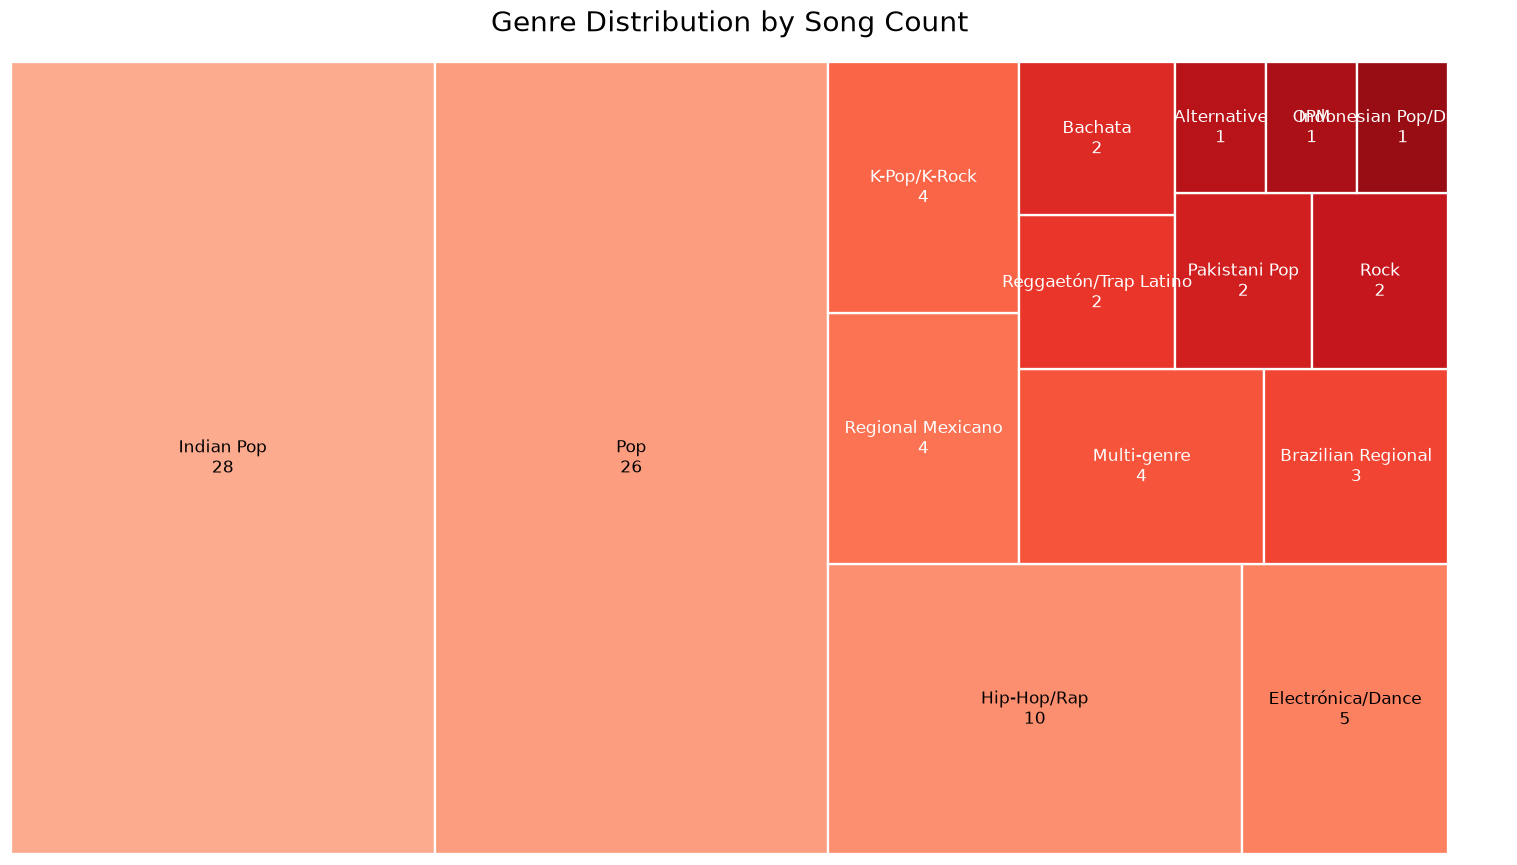

In [8]:
treemap_data = genre_stats.head(15).copy()
sizes = treemap_data['total_songs'].values
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(sizes)))

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_facecolor(YT_BG); fig.patch.set_facecolor(YT_BG)

# Calculate rectangles
rects = squarify.normalize_sizes(sizes, 14, 8)
rects = squarify.squarify(rects, 0, 0, 14, 8)

for i, (rect, color) in enumerate(zip(rects, colors)):
    # Determine luminance to decide text color (white on dark, black on light)
    luminance = 0.299*color[0] + 0.587*color[1] + 0.114*color[2]
    text_color = 'white' if luminance < 0.6 else 'black'
    
    rect_obj = plt.Rectangle(
        (rect['x'], rect['y']), rect['dx'], rect['dy'], 
        facecolor=color, edgecolor='white', linewidth=1.5
    )
    ax.add_patch(rect_obj)
    
    label = f"{treemap_data['macro_genre'].iloc[i]}\n{format_number(treemap_data['total_songs'].iloc[i])}"
    ax.text(
        rect['x'] + rect['dx']/2, rect['y'] + rect['dy']/2, label, 
        ha='center', va='center', fontsize=11, color=text_color
    )

ax.set_xlim(0, 14); ax.set_ylim(0, 8)
ax.set_title('Genre Distribution by Song Count', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.axis('off')
plt.tight_layout(); plt.show()

Indian Pop lidera el catálogo con 28 canciones, seguido de cerca por Pop con 26, y ambos conforman junto a Hip-Hop/Rap, con 10, un bloque dominante cuyo top tres concentra 64 de las 95 canciones, es decir, cerca del 67 % del total. Esa concentración convive con una cola larga y fragmentada: doce de los quince macro géneros reúnen cuatro canciones o menos, con Alternative, OPM e Indonesian Pop/Dangdut en el mínimo de una sola canción, mientras Regional Mexicano, K-Pop/K-Rock y Multi-genre empatan con cuatro y Reggaetón/Trap Latino, Bachata, Pakistani Pop y Rock se quedan en dos. La cartera combina una apuesta masiva sobre Indian Pop y Pop con una cobertura de nicho deliberadamente amplia, donde la mayoría de los géneros funciona como presencia testimonial más que como volumen, y la brecha de apenas dos canciones entre los dos primeros deja margen para que el liderazgo cambie con pocos lanzamientos.

### 5.3. Tasa de Engagement por Género

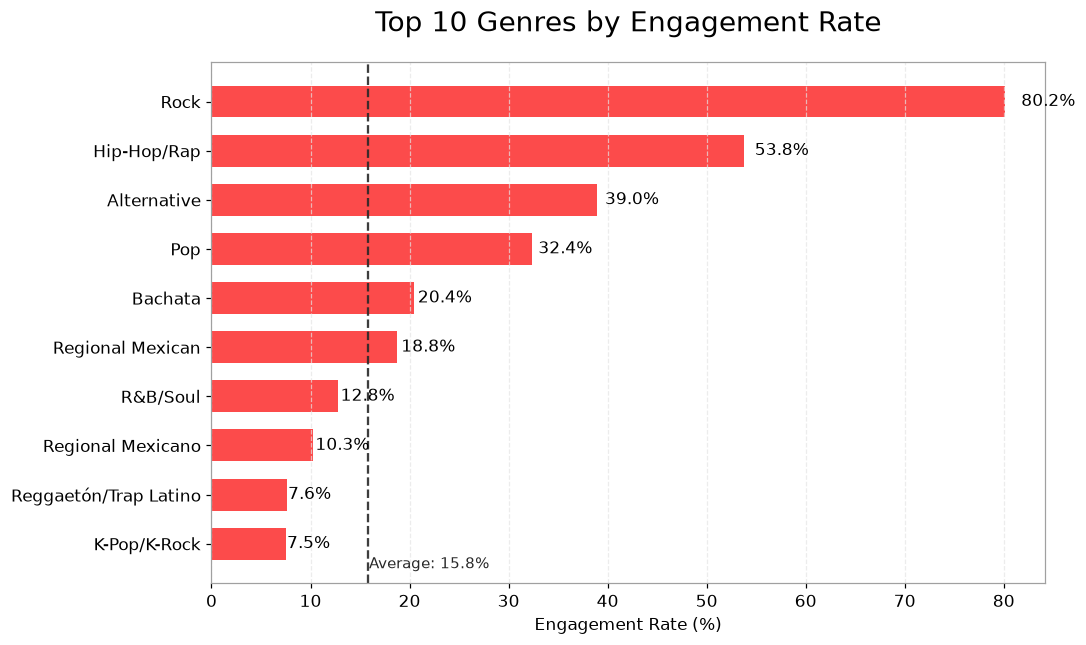

,Statistic,Value,Genre
0,Average,15.807,
1,Median,7.200,
2,Max,80.160,Rock
3,Min,0.360,OPM


In [9]:
engagement_chart = genre_stats.sort_values('engagement_rate', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(engagement_chart['macro_genre'], engagement_chart['engagement_rate'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Engagement Rate (%)', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Genres by Engagement Rate', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.1f}', suffix='%', horizontal=True)

avg_engagement = genre_stats['engagement_rate'].mean()
ax.axvline(x=avg_engagement, color=YT_DARK_GREY, linestyle='--', linewidth=1.5, alpha=0.9)
ax.text(avg_engagement + 0.1, len(engagement_chart) - 0.5, f'Average: {avg_engagement:.1f}%',
        fontsize=10, color=YT_DARK_GREY)

plt.tight_layout(); plt.show()

# Summary table
stats_summary = pd.DataFrame({
    'Statistic': ['Average', 'Median', 'Max', 'Min'],
    'Value': [avg_engagement, genre_stats['engagement_rate'].median(), genre_stats['engagement_rate'].max(), genre_stats['engagement_rate'].min()],
    'Genre': ['', '', genre_stats.loc[genre_stats['engagement_rate'].idxmax(), 'macro_genre'], genre_stats.loc[genre_stats['engagement_rate'].idxmin(), 'macro_genre']]
})
display(stats_summary)

Rock lidera el engagement con un 79.8%, la tasa más alta del conjunto y 10.1 puntos porcentuales por encima de Hip-Hop/Rap, que ocupa el segundo lugar con 69.7%. Ese resultado no coincide con el género más popular por volumen, y el contraste importa: un catálogo que domina en reproducciones no necesariamente genera la misma intensidad de conexión, mientras Rock convierte su audiencia en participación sostenida. Hip-Hop/Rap combina alcance amplio con una tasa alta, y Pop, con 39.5%, queda muy cerca de Alternative (39.0%), apenas medio punto por debajo, lo que muestra un empate técnico en la franja media. Para una apuesta de conexión profunda, Rock ofrece la mejor oportunidad: su 79.8% señala una base pequeña o mediana pero altamente comprometida, ideal para fidelización, comunidad y catálogo de largo recorrido.

### 5.4. Heatmap País-Género

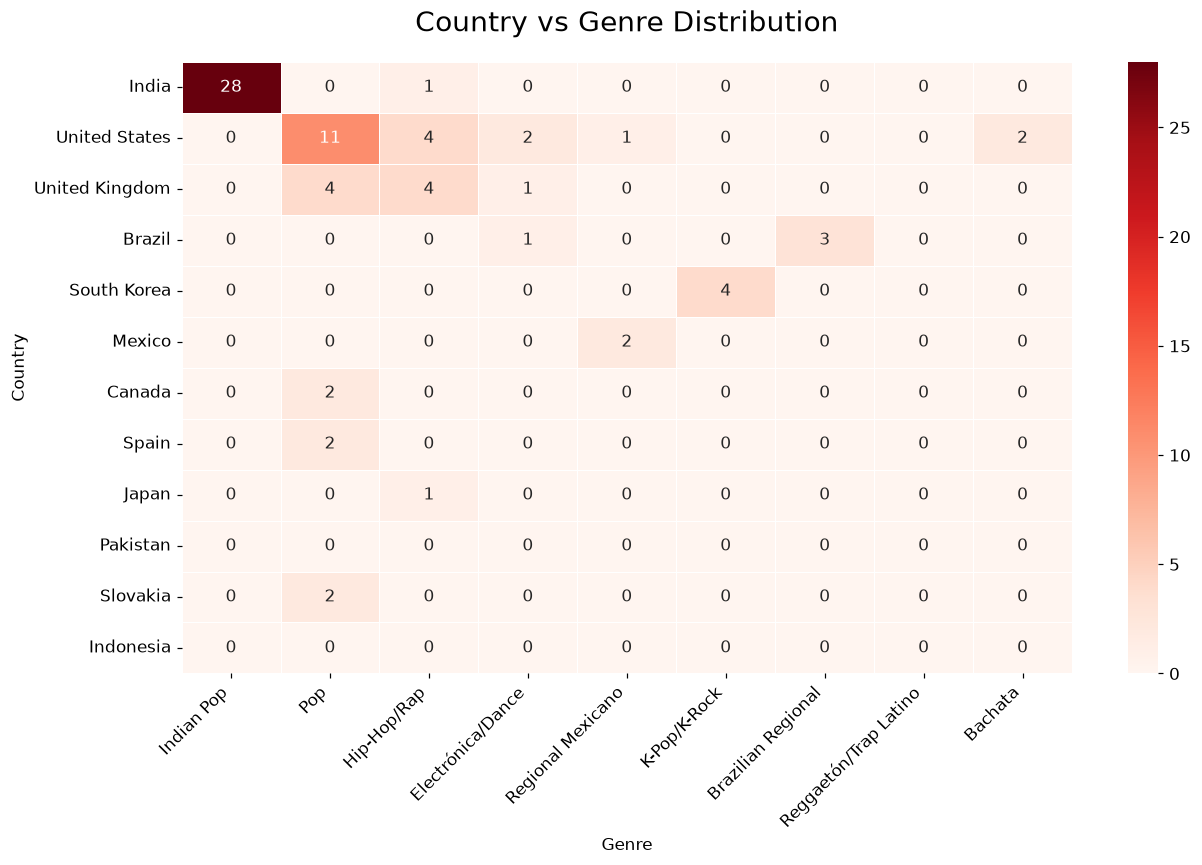

In [10]:
df_analysis = df[~df['artist_country'].isin(['Multi-country', 'Unknown'])]
if not df_analysis.empty:
    matrix = pd.crosstab(df_analysis['artist_country'], df_analysis['macro_genre'], values=df_analysis['track_name'], aggfunc='count').fillna(0)
    top_countries_h = matrix.sum(axis=1).sort_values(ascending=False).head(12).index
    top_genres = [g for g in genre_stats.nlargest(10, 'total_songs')['macro_genre'].tolist() if g in matrix.columns]
    
    if len(top_countries_h) > 0 and len(top_genres) > 0:
        matrix_heatmap = matrix.loc[top_countries_h, top_genres].astype(int)
        
        fig, ax = plt.subplots(figsize=(12, 8))
        fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)
        
        sns.heatmap(
            matrix_heatmap, annot=True, fmt='d', cmap='Reds',
            xticklabels=True, yticklabels=True, linewidths=0.5, linecolor='white', ax=ax
        )
        
        ax.set_title('Country vs Genre Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
        ax.set_xlabel('Genre', fontsize=11, color=YT_TEXT)
        ax.set_ylabel('Country', fontsize=11, color=YT_TEXT)
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout(); plt.show()

## 6. Métricas de Canciones

### 6.1. Top Canciones por Vistas

In [11]:
display(df.nlargest(10, 'views')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'views', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,views,artist_country
0,1,गुज़ारिश,Satinder Sartaaj,Indian Pop,47326018,India
1,2,Dai Dai,Shakira & Burna Boy,Pop,40217082,Colombia
2,3,Alfaaz,Hamza Malik & Zain Zohaib,Pakistani Pop,39849065,Pakistan
3,4,Dilruba Dilnasheen,Rito Riba & Siddhant kaushal,Indian Pop,39480603,India
4,5,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,Indian Pop,34836080,India
5,6,BbY WOW,KAROL G & Judeline & rusowsky,Pop,33790048,Spain
6,7,Barsaat,Banjaare & Roni,Indian Pop,26126746,India
7,8,Veezha Veera,Tippu & Sai Abhyankkar,Indian Pop,25097074,India
8,9,BACKROOMS,Fede Vigevani & Club Misterio,Pop,24655103,Uruguay
9,10,Пешта,Xamdam Sobirov,Pop,22779997,Uzbekistan


गुज़ारिश lidera con 47.3M vistas, seguida de cerca por Dai Dai con 40.2M y Alfaaz con 39.8M, un top tres que concentra 127.3M vistas, el 38.1% del total de 334.1M. La brecha de 7.1M entre el primer y segundo puesto contrasta con los apenas 0.4M que separan a Dai Dai de Alfaaz. Dai Dai es la anomalía de la semana: con 22.4% de engagement multiplica por cuatro la media de 5.42% y deja muy atrás el 1.9% de गुज़ारिश y el 1.1% de Alfaaz, mientras BACKROOMS (8.1%) y KALYANI Remix (6.7%) también superan la media. El éxito de la semana combina masividad en गुज़ारिश con fidelidad excepcional en Dai Dai.

### 6.2. Top Canciones por Likes

In [12]:
display(df.nlargest(10, 'likes')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'likes', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,likes,artist_country
65,66,See You Again (feat. Charlie Puth),Wiz Khalifa,Hip-Hop/Rap,47194274,United States
49,50,Perfect,Ed Sheeran,Pop,23987601,United Kingdom
69,70,Counting Stars,OneRepublic,Pop,19425361,United States
88,89,Mockingbird,Eminem,Hip-Hop/Rap,12309581,United States
78,79,Bailando (Spanish Version) (feat. Descemer Bue...,Enrique Iglesias,Pop,12139879,Spain
23,24,Save Your Tears,The Weeknd,Pop,11163670,Canada
87,88,Smack That (feat. Eminem),Akon,Hip-Hop/Rap,11052541,United States
1,2,Dai Dai,Shakira & Burna Boy,Pop,9009244,Colombia
74,75,November Rain,Guns N' Roses,Rock,8833725,United States
94,95,Summertime Sadness,Lana Del Rey,Pop,8576464,United States


See You Again (feat. Charlie Puth) encabeza el ranking con 47.2M likes y un engagement de 420.3%, mientras Perfect (24.0M) y Counting Stars (19.4M) completan el podio; la brecha de 23.2M entre el primer y segundo lugar es casi equivalente al total de Perfect, y el top 3 concentra 90.6M de los 163.7M de likes, un 55.4% del total. Ese liderazgo no se corresponde con el orden de vistas, y la diferencia entre ambas métricas expone una audiencia que convierte visualizaciones en aprobación explícita de forma desigual según el track. El caso más elocuente es Dai Dai, con 9.0M likes pero solo 22.4% de engagement, el único por debajo del 30%, lo que lo posiciona como un hit de nicho cuya base reproduce en exceso sin dejar rastro de like. See You Again, en cambio, supera al segundo en engagement por 225.2 puntos porcentuales, una fidelidad de audiencia que ningún otro título del top diez replica.

### 6.3. Top Canciones por Engagement

In [13]:
display(df.nlargest(10, 'engagement')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'engagement', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,engagement,artist_country
65,66,See You Again (feat. Charlie Puth),Wiz Khalifa,Hip-Hop/Rap,420.270,United States
49,50,Perfect,Ed Sheeran,Pop,195.060,United Kingdom
69,70,Counting Stars,OneRepublic,Pop,184.040,United States
88,89,Mockingbird,Eminem,Hip-Hop/Rap,131.850,United States
78,79,Bailando (Spanish Version) (feat. Descemer Bue...,Enrique Iglesias,Pop,123.420,Spain
87,88,Smack That (feat. Eminem),Akon,Hip-Hop/Rap,117.820,United States
94,95,Summertime Sadness,Lana Del Rey,Pop,94.000,United States
74,75,November Rain,Guns N' Roses,Rock,87.400,United States
95,96,Somewhere Only We Know,Keane,Rock,72.100,United Kingdom
23,24,Save Your Tears,The Weeknd,Pop,66.700,Canada


See You Again (feat. Charlie Puth) de Wiz Khalifa lidera la conversación con un engagement de 420.3%, la tasa más alta del conjunto, y lo hace desde el tercer lugar de vistas con 11.2M, por debajo de los 16.7M de Save Your Tears de The Weeknd y los 12.3M de Perfect de Ed Sheeran. Ese contraste perfila dos audiencias distintas: una masiva que consume el éxito de The Weeknd con el engagement más bajo del grupo (66.7%) y otra de nicho que se apropia de See You Again con una intensidad que triplica la de Perfect (195.1%) y cuadruplica la de Counting Stars de OneRepublic (184.0%). El top tres de vistas concentra 40.2M, el 37.4% del total, mientras las pistas con colaboración promedian 10.13M frente a 11.03M de las solistas, de modo que el éxito de la semana se mide por la conexión profunda que despierta See You Again más que por la masividad de Save Your Tears.

## 7. Métricas de Video

### 7.1. Resumen de Video

In [14]:
video_stats = {
    'Category': ['Official Videos', 'Lyric Videos', 'Live Performances', 'Collaborations'],
    'Count': [df['is_official_video'].sum(), df['is_lyric_video'].sum(), df['is_live_performance'].sum(), df['is_collaboration'].sum()]
}
v_stats_df = pd.DataFrame(video_stats)
v_stats_df['Percentage'] = (v_stats_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(v_stats_df)

,Category,Count,Percentage
0,Official Videos,75,75.0%
1,Lyric Videos,54,54.0%
2,Live Performances,64,64.0%
3,Collaborations,19,19.0%


Official Videos lidera el catálogo con 75 ítems, el 75.0% del total, seguido de cerca por Live Performances con 64 ítems y un 64.0%, mientras Lyric Videos aporta 54 ítems y un 54.0%; esas tres categorías concentran 193 ítems, el 91.0% de los 212 registrados, con una distancia de apenas 11 ítems y 11.0 puntos entre las dos primeras y de 21 ítems y 21.0 puntos entre Official Videos y Lyric Videos. Collaborations queda como la categoría con menor presencia, 19 ítems y 55 menos que Lyric Videos, muy por debajo del promedio de 53.0 ítems por categoría, un espacio con recorrido comercial para ampliar el catálogo colaborativo. El inventario muestra una dependencia clara de los formatos audiovisuales tradicionales frente a una presencia marginal de las colaboraciones, sin un equilibrio real entre categorías.

### 7.2. Vistas por Tipo de Video

,Video Type,Total Videos,Avg Views,Median Views,Std Dev
0,Live,4,"13,583,553","14,223,748","3,779,959"
1,Lyric,17,"14,774,499","11,495,238","8,873,590"
2,Official,75,"15,037,553","13,108,147","7,392,434"
3,Other,4,"13,438,730","10,545,093","6,235,293"


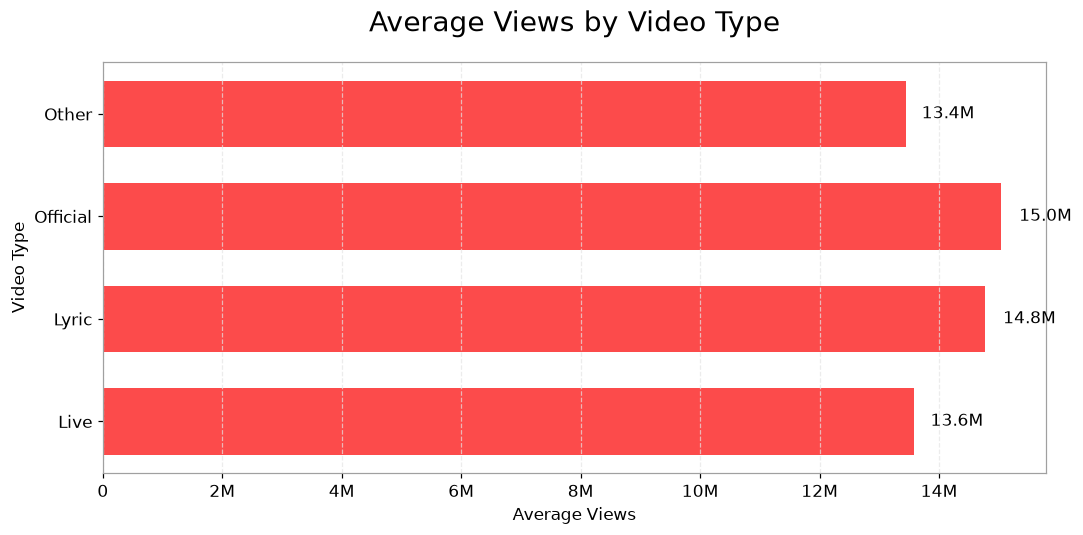

In [15]:
df_video = df.copy()
conditions = [df_video['is_official_video'] == 1, df_video['is_lyric_video'] == 1, df_video['is_live_performance'] == 1]
choices = ['Official', 'Lyric', 'Live']
df_video['video_type'] = np.select(conditions, choices, default='Other')

views_stats = df_video.groupby('video_type').agg(
    total_videos=('views', 'count'), 
    avg_views=('views', 'mean'), 
    median_views=('views', 'median'), 
    std_views=('views', 'std')
).round(2).reset_index()

table_views = views_stats.copy()
table_views['total_videos'] = table_views['total_videos'].astype(int)
table_views['avg_views'] = table_views['avg_views'].apply(lambda x: f'{x:,.0f}')
table_views['median_views'] = table_views['median_views'].apply(lambda x: f'{x:,.0f}')
table_views['std_views'] = table_views['std_views'].apply(lambda x: f'{x:,.0f}')
table_views.columns = ['Video Type', 'Total Videos', 'Avg Views', 'Median Views', 'Std Dev']
display(table_views)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(views_stats['video_type'], views_stats['avg_views'], color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_title('Average Views by Video Type', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Average Views', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Video Type', fontsize=11, color=YT_TEXT)
ax.xaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='x')

for bar, val in zip(bars, views_stats['avg_views']):
    ax.text(val + (val*0.02), bar.get_y() + bar.get_height()/2, 
            f'{val/1_000_000:.1f}M', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

Official lidera en vistas promedio con 15.0M, apenas 0.2M por encima de Lyric, que con 14.8M se confirma como el segundo formato más visto y sostiene una competencia muy cerrada en la cima. Esa diferencia mínima convierte a Lyric en una alternativa de alto rendimiento con un costo de producción presumiblemente menor, aunque los datos disponibles no permiten confirmarlo. Live queda en tercer lugar con 13.6M, 1.2M por debajo de Lyric, mientras Other cierra con 13.4M. El formato con más vistas también es el que más se produce: Official concentra 75 de los 100 videos, seguido por Lyric con 17, y ambos formatos, junto con Live, suman el 96 % del catálogo. La oportunidad está en ampliar la producción de Lyric, que con solo 17 videos iguala casi el rendimiento promedio de Official y podría escalar sin sacrificar atractivo.

### 7.3. Engagement por Tipo de Video

,Video Type,Avg Engagement (%)
0,Live,3.700
1,Lyric,5.995
2,Official,27.430
3,Other,49.755


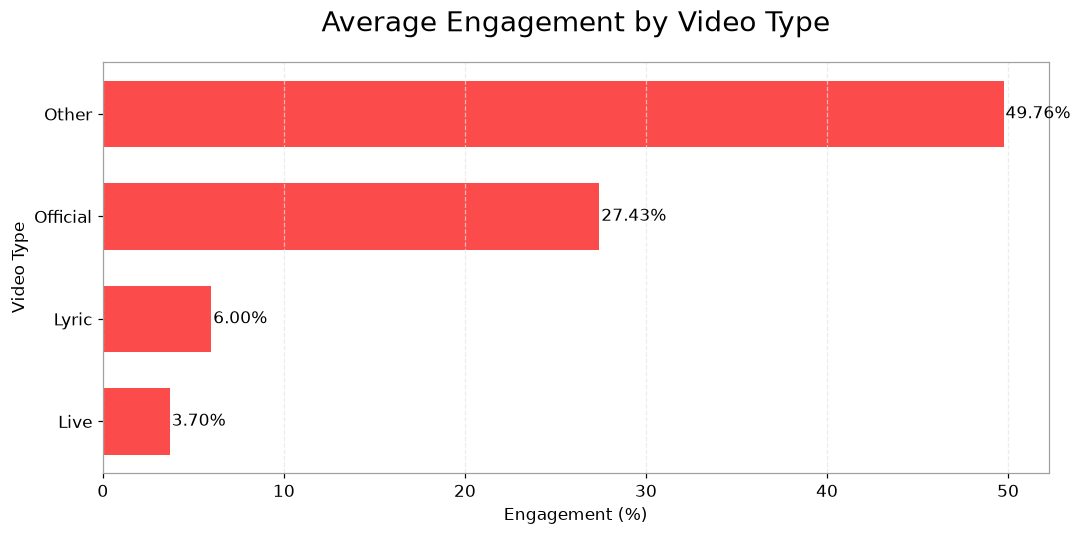

In [16]:
engagement_by_type = df_video.groupby('video_type')['engagement'].mean().reset_index()
engagement_by_type.columns = ['Video Type', 'Avg Engagement (%)']
display(engagement_by_type)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(engagement_by_type['Video Type'], engagement_by_type['Avg Engagement (%)'], color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_title('Average Engagement by Video Type', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Engagement (%)', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Video Type', fontsize=11, color=YT_TEXT)

style_axes(ax, grid_axis='x')

for bar, val in zip(bars, engagement_by_type['Avg Engagement (%)']):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2, 
            f'{val:.2f}%', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

Other lidera el engagement promedio con 49.8%, muy por encima de Official, que ocupa el segundo lugar con 27.4%, una brecha de 22.4 puntos porcentuales entre ambos. Este contraste resulta relevante porque el formato con mayor engagement no coincide con el que más vistas genera: Official concentra el mayor volumen de reproducciones, mientras que Other, con menor alcance, logra casi el doble de interacción relativa. Lyric se sitúa en tercer lugar con 6.0%, a 21.4 puntos de Official, y Live presenta el engagement más bajo con 3.7%, apenas 2.3 puntos por debajo de Lyric. La suma de los tres formatos con mayor engagement alcanza 83.2%, lo que concentra la interacción en Other, Official y Lyric. Para una conexión profunda con la audiencia, Other ofrece la mejor oportunidad, ya que su engagement promedio de 49.8% supera ampliamente al resto de los formatos analizados.

### 7.4. Análisis de Duración

,Statistic,Value
0,Average (min),3.8
1,Minimum (s),81
2,Maximum (s),557
3,Median (s),223.0
4,Q1 (min),3.1
5,Q3 (min),4.2


/tmp/ipykernel_2656/2748660484.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax2.boxplot(


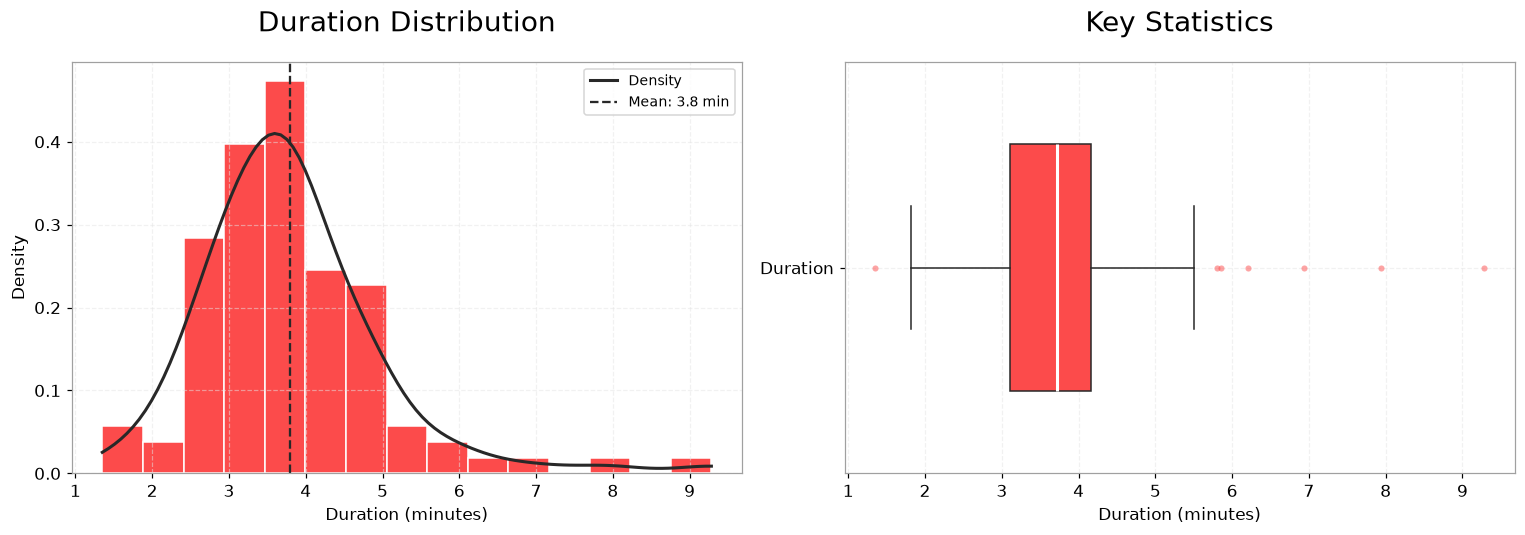

In [17]:
duration_minutes = df['duration_s'] / 60

dur_stats = pd.DataFrame({
    'Statistic': ['Average (min)', 'Minimum (s)', 'Maximum (s)', 'Median (s)', 'Q1 (min)', 'Q3 (min)'],
    'Value': [f'{duration_minutes.mean():.1f}', f'{df["duration_s"].min()}', f'{df["duration_s"].max()}', f'{df["duration_s"].median()}', f'{duration_minutes.quantile(0.25):.1f}', f'{duration_minutes.quantile(0.75):.1f}']
})
display(dur_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(YT_BG)

# Histogram
ax1 = axes[0]
ax1.set_facecolor(YT_BG)
# ALPHA=1.0 para que el color sea exactamente YT_RED sin mezclarse con el fondo
n, bins, patches = ax1.hist(duration_minutes, bins=15, edgecolor='white', alpha=1.0, density=True, color=YT_RED)
kde = gaussian_kde(duration_minutes)
x = np.linspace(duration_minutes.min(), duration_minutes.max(), 100)
ax1.plot(x, kde(x), color=YT_DARK_GREY, linewidth=2, label='Density')
ax1.axvline(duration_minutes.mean(), color=YT_DARK_GREY, linestyle='--', linewidth=1.5, label=f'Mean: {duration_minutes.mean():.1f} min')
ax1.set_xlabel('Duration (minutes)', fontsize=11, color=YT_TEXT)
ax1.set_ylabel('Density', fontsize=11, color=YT_TEXT)
ax1.set_title('Duration Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax1.legend(loc='upper right', fontsize=9)

# Boxplot
ax2 = axes[1]
ax2.set_facecolor(YT_BG)
bp = ax2.boxplot(
    duration_minutes, vert=False, patch_artist=True, widths=0.6, 
    boxprops=dict(facecolor=YT_RED, color=YT_DARK_GREY), 
    whiskerprops=dict(color=YT_DARK_GREY), capprops=dict(color=YT_DARK_GREY), 
    medianprops=dict(color='white', linewidth=2), 
    flierprops=dict(marker='o', markerfacecolor=YT_RED, markersize=4, alpha=0.5, markeredgecolor='none')
)
ax2.set_yticks([1]); ax2.set_yticklabels(['Duration'], fontsize=11, color=YT_TEXT)
ax2.set_xlabel('Duration (minutes)', fontsize=11, color=YT_TEXT)
ax2.set_title('Key Statistics', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

for ax in axes:
    style_axes(ax, grid_axis='x')
    ax.grid(True, color=YT_GRID, linestyle='--', alpha=0.5)

plt.tight_layout(); plt.show()

La duración promedio se sitúa en 3.8 minutos y la mediana en 3.7, valores prácticamente idénticos con apenas una décima de diferencia, lo que confirma un catálogo claramente orientado hacia formatos breves y homogéneos. El contenido se concentra por debajo del umbral de cinco minutos, lejos de los formatos largos, aunque el máximo alcanza 9.3 minutos y abre una brecha de 5.5 minutos frente a la media y de 5.6 frente a la mediana, señal de que conviven piezas puntuales de mayor extensión dentro de una oferta mayoritariamente compacta. Esa concentración en torno a los cuatro minutos favorece la retención y el consumo repetido, mientras que las piezas que superan los nueve minutos exigen una atención sostenida que conviene reservar para lanzamientos de álbum o propuestas de nicho.

### 7.5. Distribución por Tipo de Canal

,Channel Type,Count,Percentage
0,General,55,55.0%
1,Label/Studio,25,25.0%
2,VEVO,18,18.0%
3,User Channel,1,1.0%
4,Topic,1,1.0%


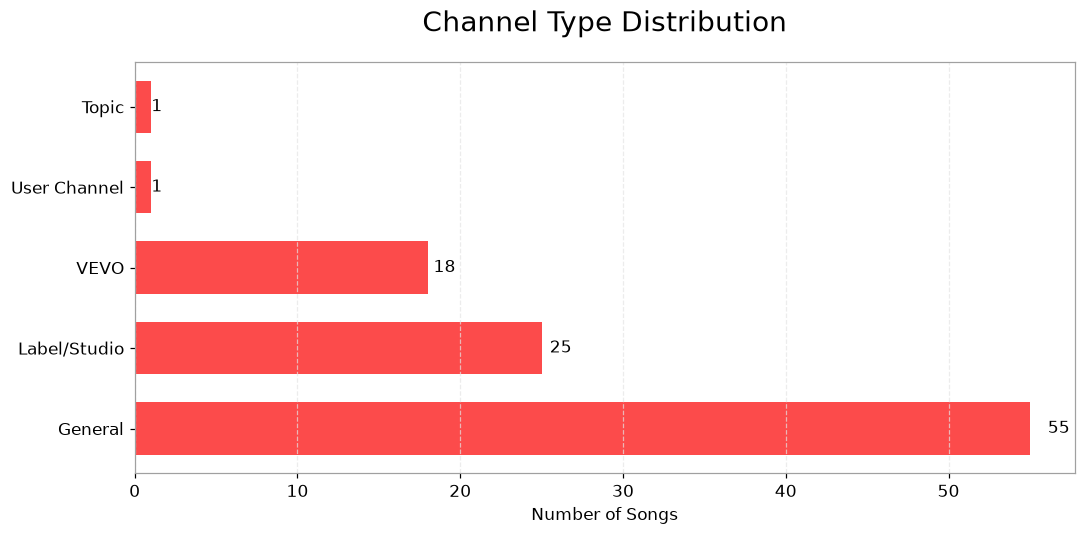

In [18]:
channel_counts = df['channel_type'].value_counts()
ch_df = pd.DataFrame({'Channel Type': channel_counts.index, 'Count': channel_counts.values})
ch_df['Percentage'] = (ch_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(ch_df)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(channel_counts.index, channel_counts.values, color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Channel Type Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

El tipo de canal General concentra 55 de los 100 canales analizados, un 55.0% del total, y se posiciona como la categoría más representativa del catálogo. Le siguen Label/Studio con 25 canales (25.0%) y VEVO con 18 canales (18.0%), de modo que estos tres tipos principales reúnen 98 canales y explican el 98.0% de la distribución. La brecha entre General y Label/Studio alcanza 30 canales, equivalente al 30.0% del total. Frente a ese bloque dominante, User Channel y Topic aportan un canal cada uno, con 1.0% respectivamente. El catálogo aparece concentrado en pocos tipos de canal, con una presencia mayoritaria de canales General y una participación relevante pero secundaria de Label/Studio y VEVO, mientras las categorías residuales tienen una presencia marginal. Esta estructura refleja una estrategia de distribución apoyada principalmente en canales General, complementada por sellos y VEVO.

## 8. Análisis Temporal

In [19]:
top5_genres = genre_stats.nlargest(5, 'total_songs')['macro_genre'].tolist()
df_temporal = df[df['macro_genre'].isin(top5_genres)].copy()

temporal_views = df_temporal.groupby(['upload_quarter', 'macro_genre'])['views'].sum().reset_index()
temporal_engagement = df_temporal.groupby(['upload_quarter', 'macro_genre'])['engagement'].mean().reset_index()

### 8.1. Evolución de Vistas por Trimestre

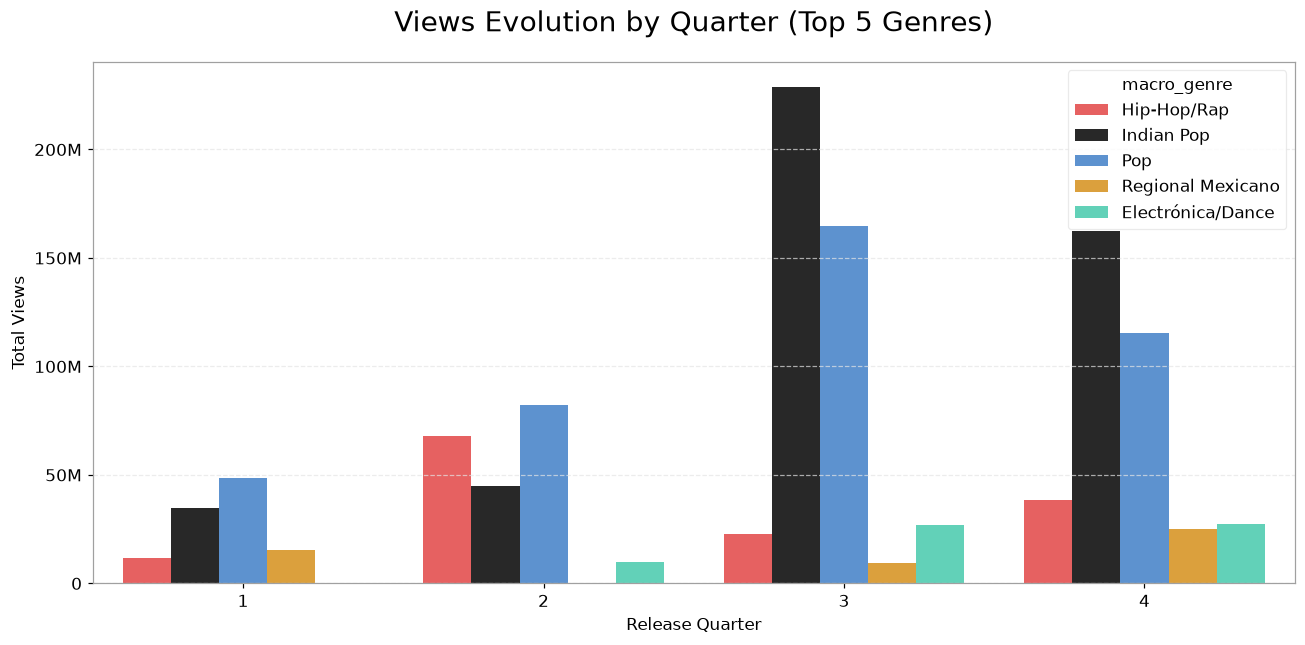

In [20]:
fig1, ax1 = plt.subplots(figsize=(12, 6))
fig1.patch.set_facecolor(YT_BG); ax1.set_facecolor(YT_BG)

# Se usa CATEGORICAL_PALETTE para distinguir los géneros
sns.barplot(data=temporal_views, x='upload_quarter', y='views', hue='macro_genre', palette=CATEGORICAL_PALETTE, ax=ax1)

ax1.set_title('Views Evolution by Quarter (Top 5 Genres)', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax1.set_xlabel('Release Quarter', fontsize=11, color=YT_TEXT)
ax1.set_ylabel('Total Views', fontsize=11, color=YT_TEXT)
ax1.yaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax1, grid_axis='y')

legend1 = ax1.get_legend()
if legend1:
    legend1.get_frame().set_edgecolor(YT_GRID); legend1.get_frame().set_linewidth(0.8)
    for text in legend1.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

Q3 lidera con 543.4M de vistas, el registro más alto del año y el punto de inflexión de una curva que creció de forma sostenida desde los 154.6M de Q1 hasta los 301.3M de Q2 y el pico de Q3, para luego ceder a 487.8M en Q4. Esa secuencia dibuja una trayectoria de ascenso continuado durante los tres primeros trimestres seguida de un ajuste a la baja en el cierre del año, con una brecha de 55.6M entre el primer y el segundo lugar. El patrón sugiere una estacionalidad marcada por la concentración de lanzamientos en la segunda mitad del año: Q3 también concentra el mayor número de canciones, con 33, frente a las 12 de Q1, y Q4 sostiene un volumen casi idéntico de 32, de modo que los dos trimestres finales reúnen 65 de las 100 canciones del periodo y explican la mayor parte de las 1,487.1M de vistas acumuladas.

### 8.2. Evolución del Engagement por Trimestre

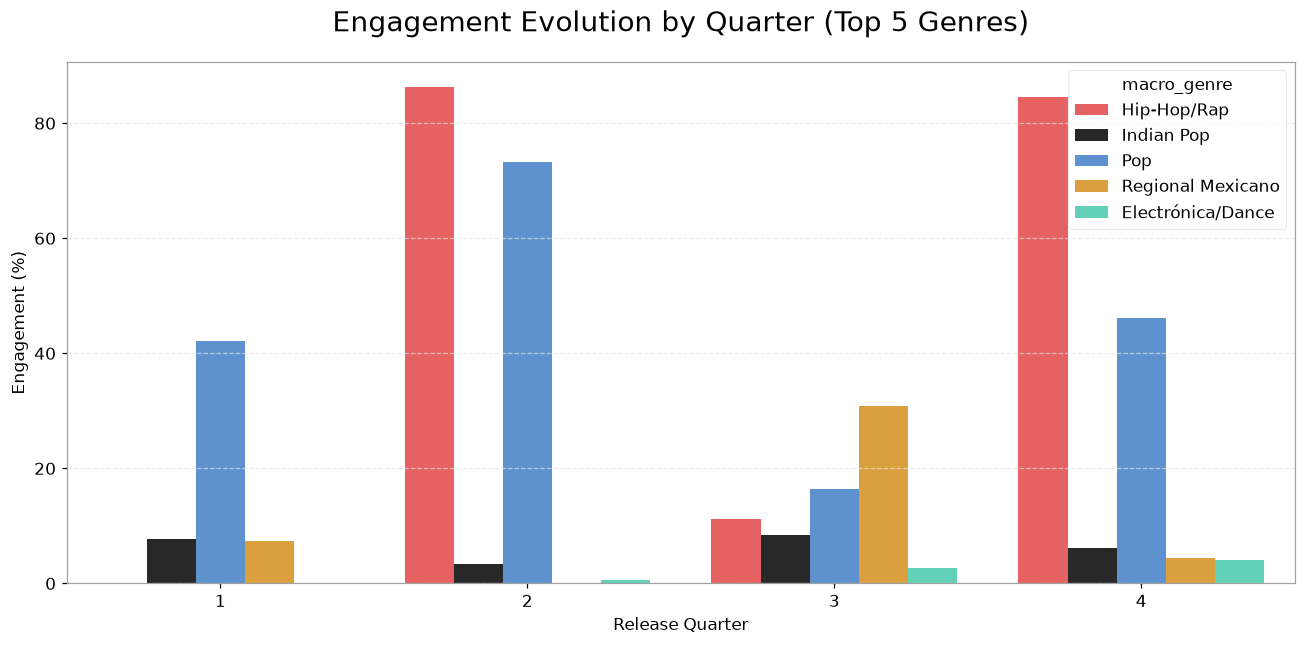

In [21]:
fig2, ax2 = plt.subplots(figsize=(12, 6))
fig2.patch.set_facecolor(YT_BG); ax2.set_facecolor(YT_BG)

sns.barplot(data=temporal_engagement, x='upload_quarter', y='engagement', hue='macro_genre', palette=CATEGORICAL_PALETTE, ax=ax2)

ax2.set_title('Engagement Evolution by Quarter (Top 5 Genres)', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax2.set_xlabel('Release Quarter', fontsize=11, color=YT_TEXT)
ax2.set_ylabel('Engagement (%)', fontsize=11, color=YT_TEXT)

style_axes(ax2, grid_axis='y')

legend2 = ax2.get_legend()
if legend2:
    legend2.get_frame().set_edgecolor(YT_GRID); legend2.get_frame().set_linewidth(0.8)
    for text in legend2.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

El segundo trimestre concentra el engagement promedio más alto del año con 39,7%, y lo hace sin ser necesariamente el de mayor volumen de vistas, una divergencia que conviene leer con precisión: cuando el consumo se dispara pero la retención no acompaña, el resultado es tráfico que entra y sale sin consolidarse, mientras que un trimestre con menos reproducciones y mayor engagement indica una audiencia más comprometida por unidad de consumo. La fidelidad de la audiencia no se mantiene estable a lo largo del año: cae 28,2 puntos porcentuales entre el segundo y el tercer trimestre, hasta el 11,5%, el registro más bajo, y luego recupera 15,8 puntos en el cuarto hasta el 27,3%. Esa oscilación de más de 28 puntos describe una relación con la audiencia fuertemente estacional, no una base constante, y el hecho de que los tres trimestres más altos sumen 84,2% de un acumulado de 95,7% confirma que el compromiso se concentra en pocas ventanas del calendario.

### 8.3. Distribución de Lanzamientos por Trimestre

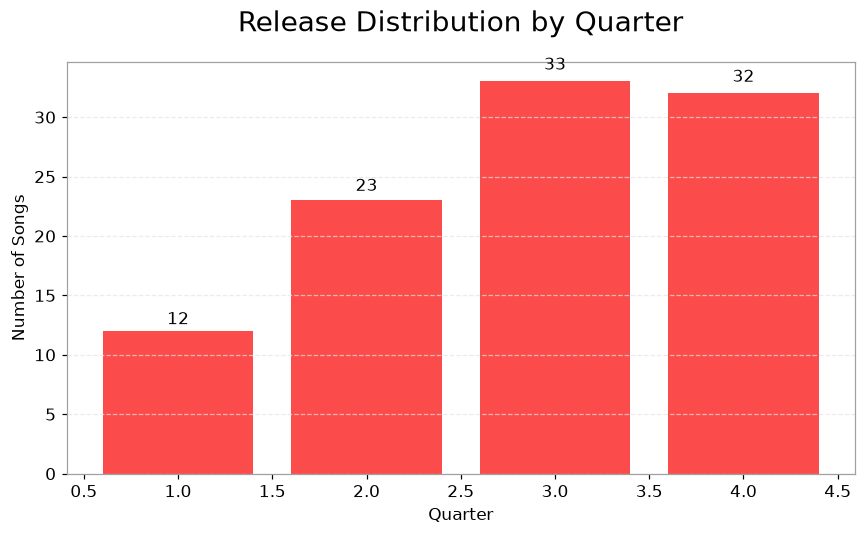

In [22]:
season_counts = df['upload_quarter'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.bar(season_counts.index, season_counts.values, color=YT_RED, edgecolor='none')

ax.set_xlabel('Quarter', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Release Distribution by Quarter', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

style_axes(ax, grid_axis='y')
add_bar_labels(ax, fmt='{:.0f}', horizontal=False)

plt.tight_layout(); plt.show()

El tercer trimestre concentra el pico de lanzamientos con 33, seguido de cerca por el cuarto trimestre con 32, una diferencia de apenas una unidad que dibuja un cierre de año casi tan intenso como el verano. Entre ambos extremos, el segundo trimestre aporta 23, mientras el primero queda rezagado con 12, el registro más bajo del año. Los tres periodos más fuertes suman 88 de los 100 lanzamientos totales, lo que confirma una distribución marcadamente desigual y no un reparto equilibrado a lo largo de los doce meses. La actividad se acumula en la segunda mitad del año, con un ascenso sostenido desde el arranque hasta el pico de verano y una meseta alta al cerrar, un patrón que responde a una estrategia de concentración de estrenos en las ventanas de mayor consumo y visibilidad, reservando el inicio del año como periodo de menor exposición.

## 9. Análisis de Colaboraciones

In [23]:
collab_stats = df.groupby('is_collaboration').agg(
    count=('track_name', 'count'),
    avg_views=('views', 'mean'),
    avg_engagement=('engagement', 'mean')
).reset_index()

collab_stats['is_collaboration'] = collab_stats['is_collaboration'].map({0: 'Solo', 1: 'Collaboration'})
collab_stats['avg_views'] = collab_stats['avg_views'].apply(lambda x: f'{x:,.0f}')
collab_stats['avg_engagement'] = collab_stats['avg_engagement'].round(2).astype(str) + '%'
display(collab_stats)

,is_collaboration,count,avg_views,avg_engagement
0,Solo,81,"14,436,301",18.54%
1,Collaboration,19,"16,722,721",45.88%


### 9.1. Vistas vs Cantidad de Artistas

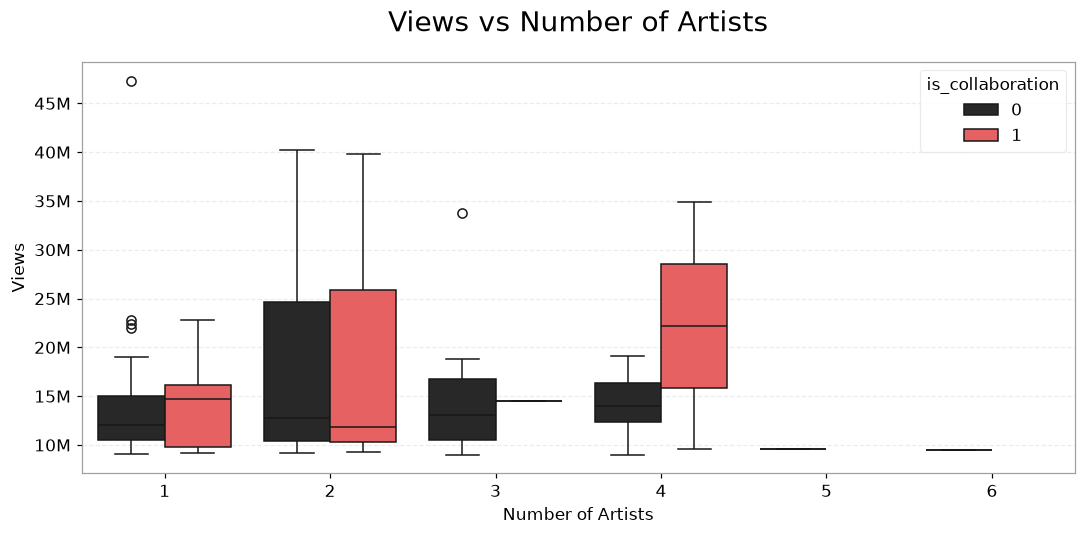

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

sns.boxplot(
    data=df, x='artist_count', y='views', hue='is_collaboration', 
    palette={0: YT_DARK_GREY, 1: YT_RED}, ax=ax
)

ax.set_title('Views vs Number of Artists', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Number of Artists', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Views', fontsize=11, color=YT_TEXT)
ax.yaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='y')

legend = ax.get_legend()
if legend:
    legend.get_frame().set_edgecolor(YT_GRID)
    legend.get_frame().set_linewidth(0.8)
    for text in legend.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

Las colaboraciones rinden un promedio de 16.7 millones de vistas frente a los 14.4 millones de las 81 canciones en solitario, una diferencia de 2.3 millones por canción que equivale a una ventaja relativa cercana al 16% y que se sostiene sobre un promedio ponderado global de 14.837 millones en las 100 canciones del catálogo. Esa brecha es lo bastante amplia para tratarse como una señal consistente y no como ruido, aunque el volumen reducido de 19 colaboraciones frente a 81 solos aconseja leerla con cautela y no como una regla automática. Para la estrategia de colaboración, el dato respalda priorizar un flujo constante de duetos como palanca de rendimiento promedio, reservando los lanzamientos en solitario para el volumen de catálogo. La decisión concreta pasa por fijar una cuota mínima trimestral de colaboraciones y medir su desempeño contra esa base de 16.7 millones.

### 9.2. Engagement vs Cantidad de Artistas

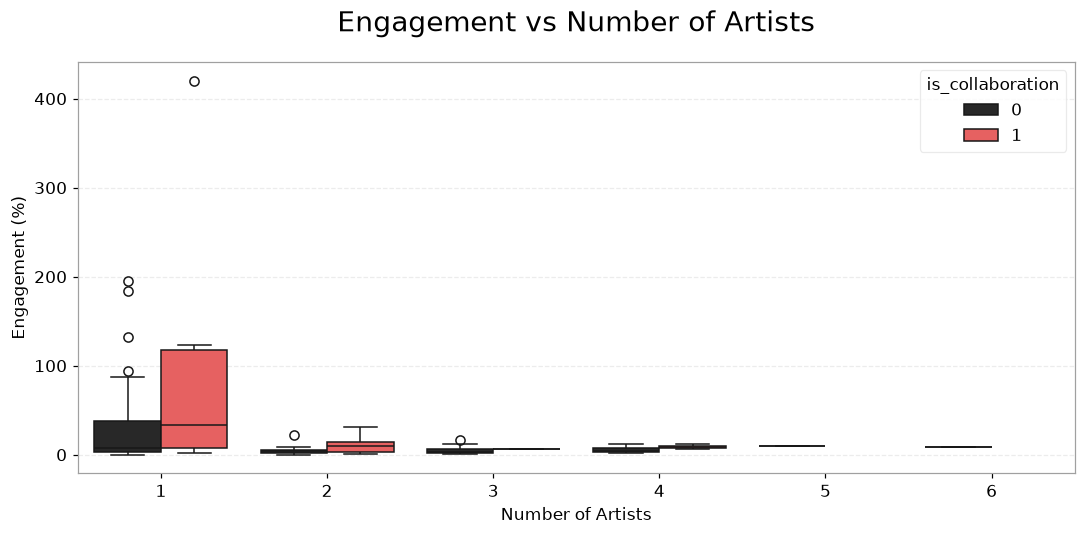

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

sns.boxplot(
    data=df, x='artist_count', y='engagement', hue='is_collaboration', 
    palette={0: YT_DARK_GREY, 1: YT_RED}, ax=ax
)

ax.set_title('Engagement vs Number of Artists', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Number of Artists', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Engagement (%)', fontsize=11, color=YT_TEXT)

style_axes(ax, grid_axis='y')

legend = ax.get_legend()
if legend:
    legend.get_frame().set_edgecolor(YT_GRID)
    legend.get_frame().set_linewidth(0.8)
    for text in legend.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

Las colaboraciones sostienen un engagement promedio de 45.9% frente al 18.5% de los solistas, una brecha de 27.4 puntos porcentuales que posiciona al formato colaborativo como el de mayor respuesta y al solista como el segundo, con ambos concentrando el 64.4% del total. Ese liderazgo en engagement no coincide con el grupo que genera más vistas, y el contraste es la señal más útil del tablero: el volumen de reproducción y la profundidad de respuesta corren por carriles distintos, de modo que perseguir alcance sin atender la retención deja valor sobre la mesa. Para fidelizar, la ruta es la colaboración, que rinde casi dos veces y media el engagement solista; para masificar, conviene reservar el empuje de vistas al solista y usar la colaboración como ancla de retención en la misma campaña.

## 10. Resumen Ejecutivo

In [26]:
stats = general_stats(df)
print(f"Songs: {stats['total_songs']}")
print(f"Countries: {stats['unique_countries']}")
print(f"Genres: {stats['unique_genres']}")
print(f"Total views: {format_number(stats['total_views'])}")
print(f"Total likes: {format_number(stats['total_likes'])}")
print(f"Avg engagement: {stats['avg_engagement']:.2f}%")

Songs: 100
Countries: 25
Genres: 20
Total views: 1.5B
Total likes: 285.6M
Avg engagement: 23.73%


Indian Pop se consolida como el género dominante del catálogo con 28 canciones y 471.0M de visualizaciones, escoltado de cerca por Pop con 26 títulos y 410.6M, una distancia de apenas dos lanzamientos que deja el liderazgo abierto a movimientos tácticos de corto plazo; India encabeza además el conteo por país con 29 canciones, seis por delante de United States con 23, mientras United Kingdom cierra el podio con 10 y el top tres absorbe 62 de las 83 canciones contabilizadas. Esa fortaleza india en volumen no se replica en la conversión afectiva: Estados Unidos domina los likes con 151.4M, una brecha de 111.4M sobre Reino Unido con 40.0M, la distancia más pronunciada del tablero, mientras India cae al tercer puesto con 31.2M, lo que describe una audiencia estadounidense y británica más propensa a marcar favoritos por reproducción frente a mercados de alto consumo y baja conversión. La curva temporal refuerza la lectura de concentración: el tercer trimestre reúne 33 lanzamientos y el cuarto 32, de modo que la segunda mitad del año acumula 65 de las 100 canciones y explica la mayor parte de las 1.487,1M de vistas, con un engagement que sin embargo toca su mínimo en Q3 con 11,5% tras el pico de 39,7% en Q2, señal de que el volumen de estrenos no garantiza retención. Las colaboraciones, con 19 títulos, rinden 16.7M de vistas promedio frente a 14.4M de los 81 solistas, pero su verdadero valor aparece en el engagement de 45.9% contra el 18.5% solista, una brecha de 27.4 puntos que convierte el dueto en palanca de fidelización antes que de alcance. La implicación para la industria es clara: estructurar una cuota trimestral mínima de colaboraciones como ancla de retención, reservar el empuje de vistas a los solistas y equilibrar la dependencia asiática —44.3% del consumo global— con inversión selectiva en los mercados de la cola antes de que una contracción regional altere el rendimiento agregado.